In [ ]:
!nvidia-smi

Thu Oct  8 09:08:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

dataset_path = "PPE-Detection-with-Gloves-9"
print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Dataset contents:", os.listdir(dataset_path))

GPU available: True
GPU: Tesla T4
Dataset exists: False


In [ ]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir("/content"))


Current directory: /content
Files here: ['.config', 'sample_data']


In [ ]:
import os

dataset_path = "PPE-Detection-with-Gloves-9"

if os.path.exists(dataset_path):
    print("Dataset found!")
    print("Contents:", os.listdir(dataset_path))
else:
    print("Dataset not found. We need to download it again.")

Dataset not found. We need to download it again.


In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 137.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 7.0 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [ ]:
!pip install roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="ZiF1HQeSxOdZnHeXI6UJ")
project = rf.workspace("ppe-detection-82plm").project("ppe-detection-with-gloves")
version = project.version(9)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PPE-Detection-with-Gloves-9 in yolov8:: 100%|██████████| 1340/1340 [00:00<00:00, 8667.65it/s]


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="ZiF1HQeSxOdZnHeXI6UJ")
project = rf.workspace("ppe-detection-82plm").project("ppe-detection-with-gloves")
version = project.version(9)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 125.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PPE-Detection-with-Gloves-9 in yolov8:: 100%|██████████| 1340/1340 [00:00<00:00, 8507.56it/s]


In [ ]:
import os

dataset_path = dataset.location

print("Dataset exists:", os.path.exists(dataset_path))
print("Dataset contents:", os.listdir(dataset_path))

Dataset exists: True
Dataset contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


In [ ]:
import yaml
from pathlib import Path

data_yaml = Path(dataset.location) / "data.yaml"

with open(data_yaml, "r") as f:
    data_config = yaml.safe_load(f)

print(data_config)

{'names': ['Gloves', 'Vest', 'helmet', 'person'], 'nc': 4, 'roboflow': {'license': 'CC BY 4.0', 'project': 'ppe-detection-with-gloves', 'url': 'https://universe.roboflow.com/ppe-detection-82plm/ppe-detection-with-gloves/dataset/9', 'version': 9, 'workspace': 'ppe-detection-82plm'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [ ]:
from pathlib import Path
import yaml

data_yaml = Path(dataset.location) / "data.yaml"

with open(data_yaml, "r") as f:
    config = yaml.safe_load(f)

for split in ["train", "val", "test"]:
    image_dir = (data_yaml.parent / config[split]).resolve()
    print(f"{split}: {image_dir}")
    print("Exists:", image_dir.exists())
    print("Images:", len(list(image_dir.glob("*"))))
    print()

train: /content/train/images
Exists: False
Images: 0

val: /content/valid/images
Exists: False
Images: 0

test: /content/test/images
Exists: False
Images: 0



In [ ]:
import os

print("Dataset location:", dataset.location)
print("Dataset folder contents:", os.listdir(dataset.location))

for root, dirs, files in os.walk("/content"):
    if "data.yaml" in files:
        print("\nFound data.yaml:", os.path.join(root, "data.yaml"))

Dataset location: /content/PPE-Detection-with-Gloves-9
Dataset folder contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']

Found data.yaml: /content/PPE-Detection-with-Gloves-9/data.yaml


In [ ]:
from pathlib import Path
import yaml

data_yaml = Path(dataset.location) / "data.yaml"

with open(data_yaml, "r") as f:
    config = yaml.safe_load(f)

config["path"] = str(Path(dataset.location).resolve())
config["train"] = "train/images"
config["val"] = "valid/images"
config["test"] = "test/images"

with open(data_yaml, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Updated data.yaml successfully!")
print(config)

Updated data.yaml successfully!
{'names': ['Gloves', 'Vest', 'helmet', 'person'], 'nc': 4, 'roboflow': {'license': 'CC BY 4.0', 'project': 'ppe-detection-with-gloves', 'url': 'https://universe.roboflow.com/ppe-detection-82plm/ppe-detection-with-gloves/dataset/9', 'version': 9, 'workspace': 'ppe-detection-82plm'}, 'test': 'test/images', 'train': 'train/images', 'val': 'valid/images', 'path': '/content/PPE-Detection-with-Gloves-9'}


In [ ]:
from pathlib import Path
import yaml

with open(data_yaml, "r") as f:
    config = yaml.safe_load(f)

for split in ["train", "val", "test"]:
    image_dir = Path(config["path"]) / config[split]
    images = list(image_dir.glob("*"))

    print(f"{split}: Exists = {image_dir.exists()}, Images = {len(images)}")

train: Exists = True, Images = 501
val: Exists = True, Images = 119
test: Exists = True, Images = 44


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(data_yaml),
    epochs=25,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="ppe_baseline"
)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.4 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(data_yaml),
    epochs=25,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="ppe_baseline"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PPE-Detection-with-Gloves-9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscri

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="ZiF1HQeSxOdZnHeXI6UJ")
project = rf.workspace("ppe-detection-82plm").project("ppe-detection-with-gloves")
version = project.version(9)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PPE-Detection-with-Gloves-9 in yolov8:: 100%|██████████| 1340/1340 [00:00<00:00, 9493.00it/s]


results.png


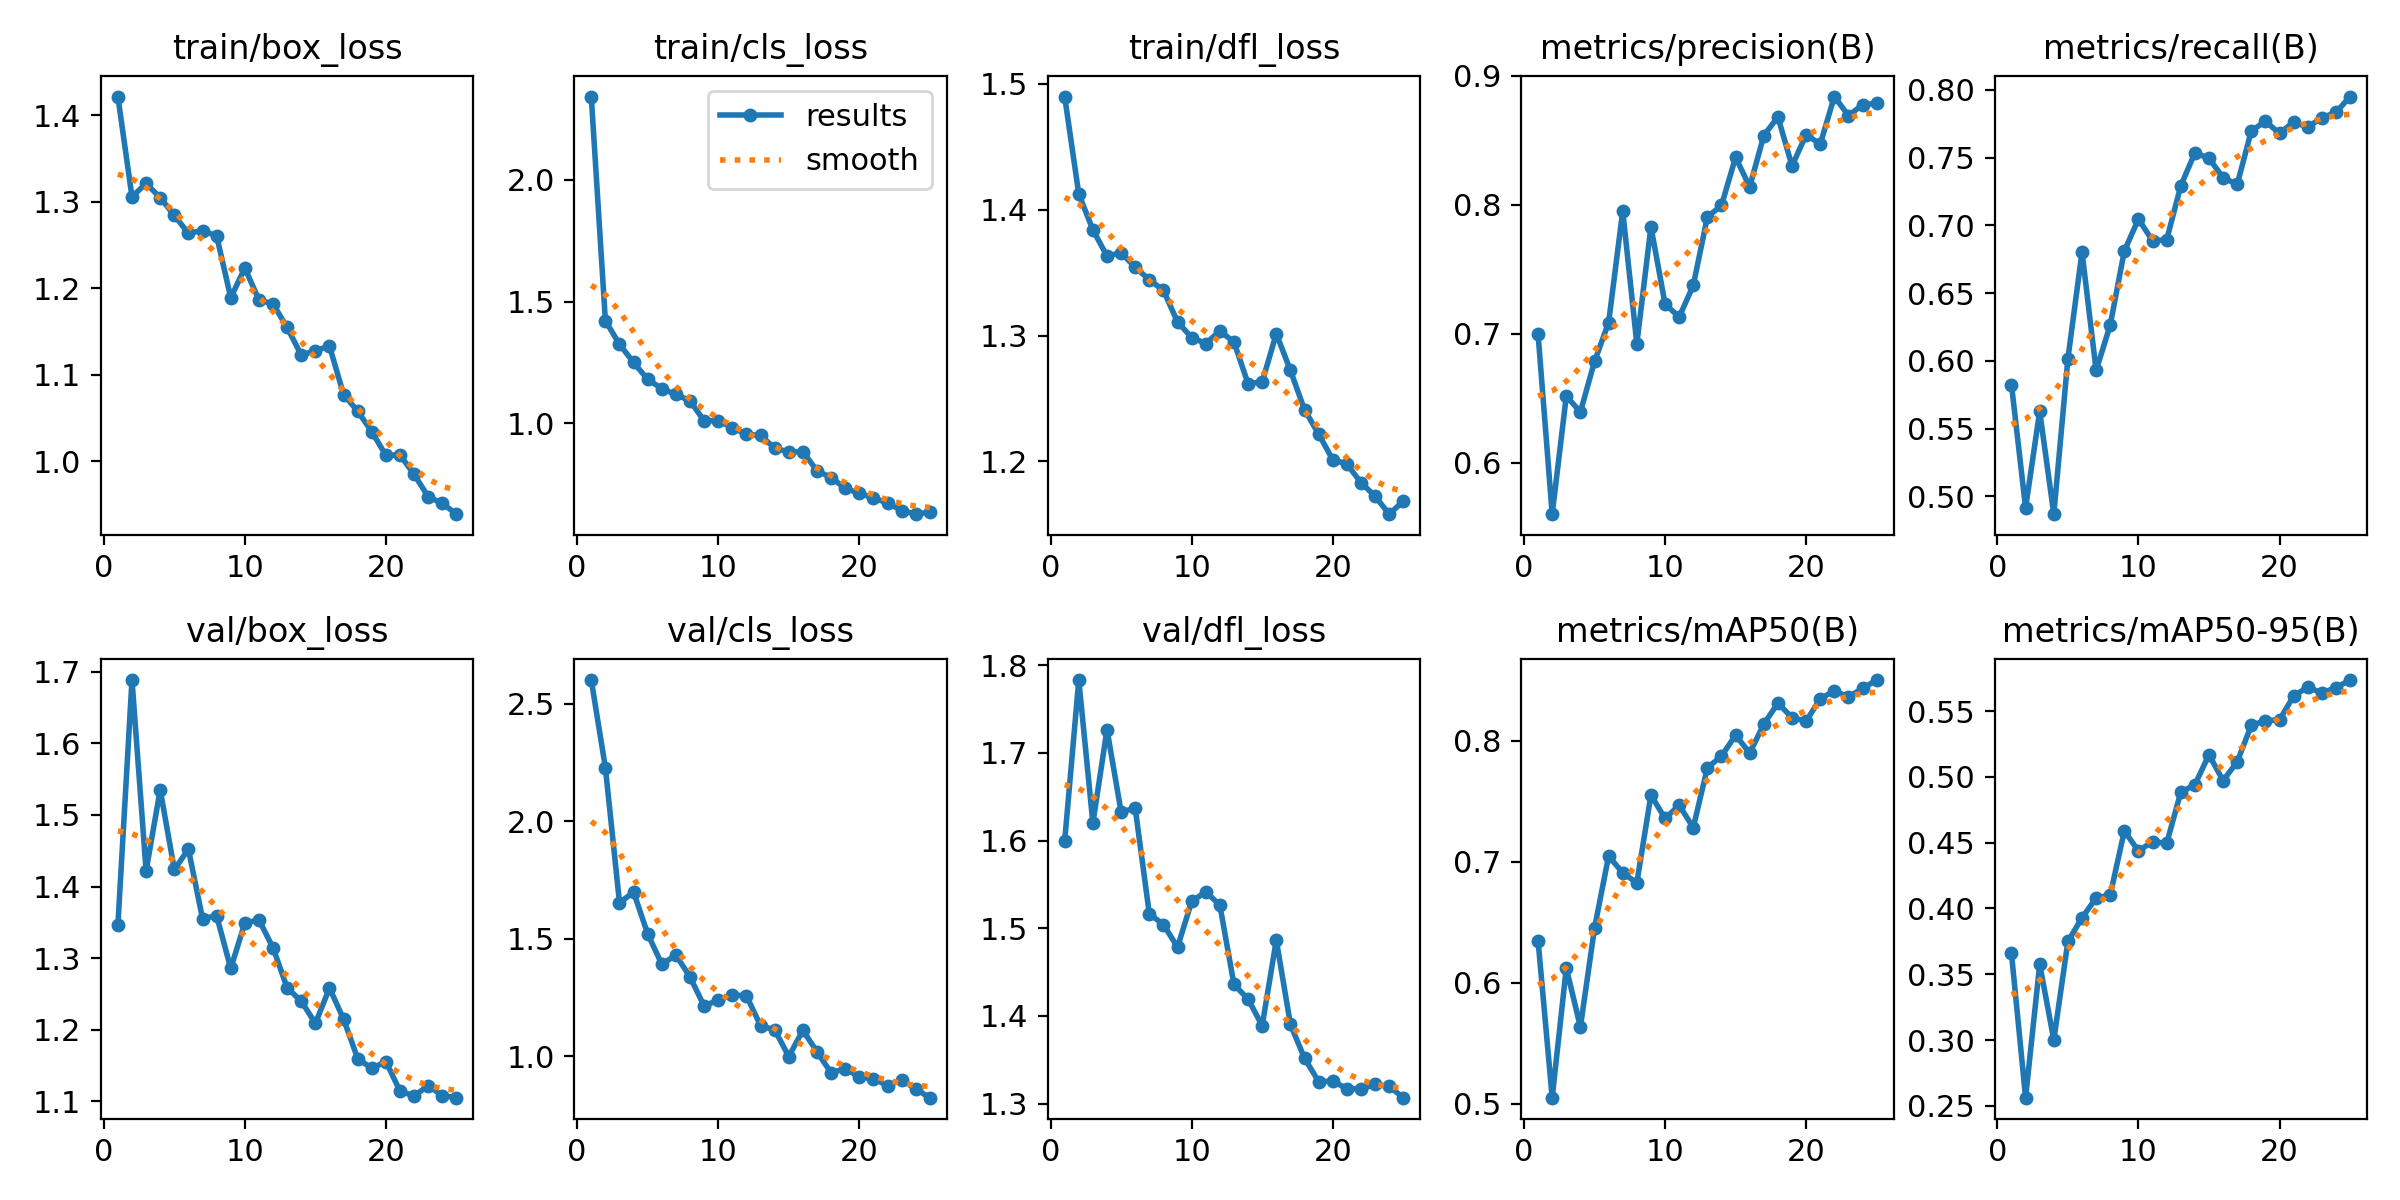

confusion_matrix.png


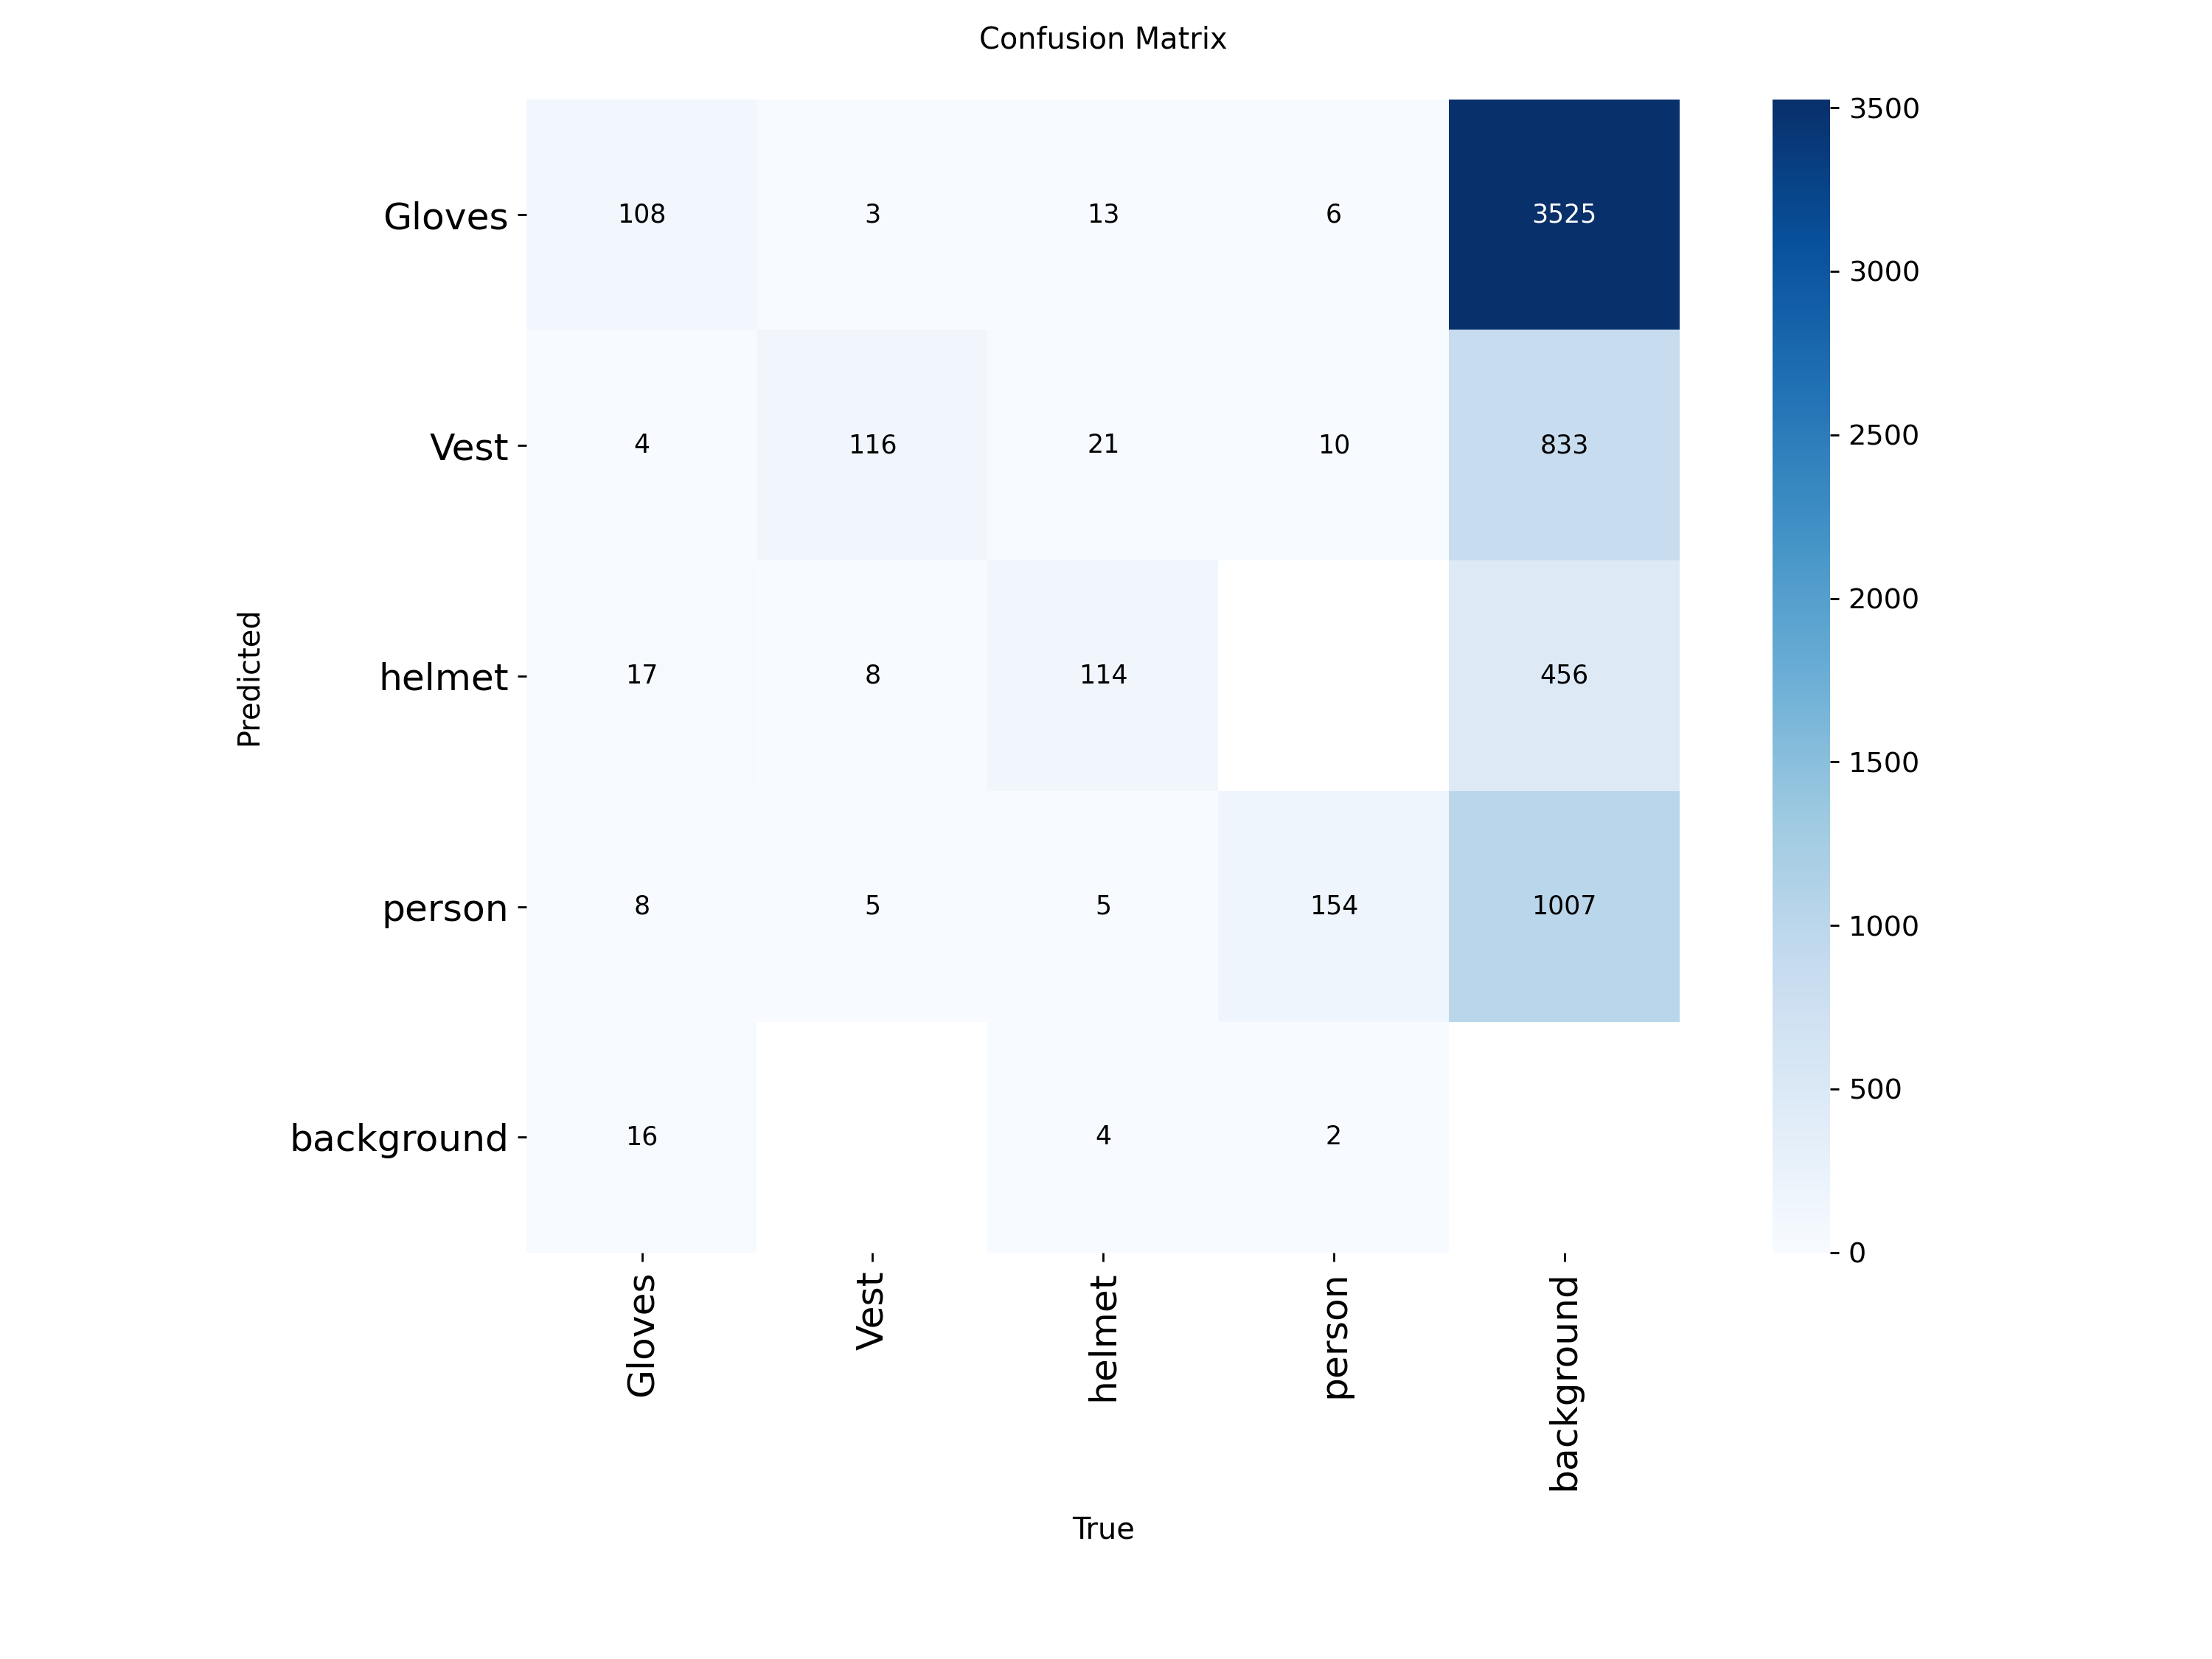

PR_curve.png not found


In [ ]:
from IPython.display import Image, display
from pathlib import Path

results_dir = Path("/content/runs/ppe_baseline")

for filename in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    filepath = results_dir / filename
    if filepath.exists():
        print(filename)
        display(Image(filename=str(filepath)))
    else:
        print(f"{filename} not found")

In [ ]:
from ultralytics import YOLO

best_model = YOLO("/content/runs/ppe_baseline/weights/best.pt")

test_results = best_model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    device=0,x
    project="/content/runs",
    name="ppe_test_evaluation"
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1278.8±447.0 MB/s, size: 38.2 KB)
val: Scanning /content/PPE-Detection-with-Gloves-9/test/labels... 44 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 2.0Kit/s 0.0s
val: New cache created: /content/PPE-Detection-with-Gloves-9/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.1it/s 2.6s
                   all         44        270      0.766      0.767        0.8      0.468
                Gloves         25         51      0.547       0.51      0.543      0.271
                  Vest         31         67      0.839      0.777       0.82      0.521
                helmet         32         73      0.918      0.922      0.937      0.565
                person         35         79      0

In [ ]:
from google.colab import files

files.download("/content/runs/ppe_baseline/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.listdir("PPE-Detection-with-Gloves-9"))

['valid', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'README.dataset.txt']


In [ ]:
import os

for split in ["train", "valid", "test"]:
    folder = os.path.join(dataset_path, split)

    print(f"\n{split.upper()}")

    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder not found!")


TRAIN
['labels', 'images']

VALID
['labels', 'images']

TEST
['labels', 'images']


In [ ]:
from pathlib import Path

yaml_path = Path(dataset_path) / "data.yaml"

print(yaml_path.read_text())

names:
- Gloves
- Vest
- helmet
- person
nc: 4
roboflow:
  license: CC BY 4.0
  project: ppe-detection-with-gloves
  url: https://universe.roboflow.com/ppe-detection-82plm/ppe-detection-with-gloves/dataset/9
  version: 9
  workspace: ppe-detection-82plm
test: ../test/images
train: ../train/images
val: ../valid/images



In [ ]:
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "test"]:
    image_dir = Path(dataset_path) / split / "images"

    if image_dir.exists():
        images = [
            f for f in image_dir.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        ]
        print(f"{split}: {len(images)} images")
    else:
        print(f"{split}: image folder not found")

train: 501 images
valid: 119 images
test: 44 images


In [ ]:
from pathlib import Path
from collections import Counter
import yaml

root = Path(dataset_path)

with open(root / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, dict):
    class_names = {
        int(k): v for k, v in names.items()
    }
else:
    class_names = {
        i: name for i, name in enumerate(names)
    }

print("Classes:", class_names)

for split in ["train", "valid", "test"]:
    label_dir = root / split / "labels"

    counts = Counter()
    labelled_objects = 0
    empty_files = 0
    malformed_lines = 0

    if not label_dir.exists():
        print(f"\n{split}: labels folder not found")
        continue

    for file in label_dir.glob("*.txt"):
        content = file.read_text().strip()

        if not content:
            empty_files += 1
            continue

        for line in content.splitlines():
            parts = line.split()

            try:
                class_id = int(parts[0])
                if len(parts) != 5:
                    malformed_lines += 1
                    continue

                counts[class_id] += 1
                labelled_objects += 1

            except (ValueError, IndexError):
                malformed_lines += 1

    print(f"\n{split.upper()}")
    print("Labelled objects:", labelled_objects)
    print("Empty label files:", empty_files)
    print("Malformed annotation lines:", malformed_lines)

    for class_id, name in class_names.items():
        print(f"  {name}: {counts[class_id]}")

Classes: {0: 'Gloves', 1: 'Vest', 2: 'helmet', 3: 'person'}

TRAIN
Labelled objects: 3597
Empty label files: 0
Malformed annotation lines: 0
  Gloves: 830
  Vest: 821
  helmet: 947
  person: 999

VALID
Labelled objects: 614
Empty label files: 0
Malformed annotation lines: 0
  Gloves: 153
  Vest: 132
  helmet: 157
  person: 172

TEST
Labelled objects: 270
Empty label files: 0
Malformed annotation lines: 0
  Gloves: 51
  Vest: 67
  helmet: 73
  person: 79


In [ ]:
from pathlib import Path

root = Path(dataset_path)
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "test"]:
    image_dir = root / split / "images"
    label_dir = root / split / "labels"

    if not image_dir.exists() or not label_dir.exists():
        print(f"{split}: missing images or labels folder")
        continue

    image_stems = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    }

    label_stems = {
        p.stem for p in label_dir.glob("*.txt")
    }

    missing_labels = image_stems - label_stems
    orphan_labels = label_stems - image_stems

    print(f"\n{split.upper()}")
    print("Images:", len(image_stems))
    print("Label files:", len(label_stems))
    print("Images without label files:", len(missing_labels))
    print("Labels without matching images:", len(orphan_labels))

    if missing_labels:
        print("Examples missing labels:", list(missing_labels)[:5])

    if orphan_labels:
        print("Examples of orphan labels:", list(orphan_labels)[:5])


TRAIN
Images: 501
Label files: 501
Images without label files: 0
Labels without matching images: 0

VALID
Images: 119
Label files: 119
Images without label files: 0
Labels without matching images: 0

TEST
Images: 44
Label files: 44
Images without label files: 0
Labels without matching images: 0


In [ ]:
import os

print(os.listdir("PPE-Detection-with-Gloves-9"))

['data.yaml', 'test', 'train', 'valid', 'README.dataset.txt', 'README.roboflow.txt']


In [ ]:
import os

for folder in ["train", "valid", "test"]:
    print(f"\n{folder}:")
    print(os.listdir(f"PPE-Detection-with-Gloves-9/{folder}"))


train:
['images', 'labels']

valid:
['images', 'labels']

test:
['images', 'labels']


In [ ]:
data.yaml

NameError: name 'data' is not defined

In [ ]:
with open("PPE-Detection-with-Gloves-9/data.yaml", "r") as f:
    print(f.read())

names:
- Gloves
- Vest
- helmet
- person
nc: 4
roboflow:
  license: CC BY 4.0
  project: ppe-detection-with-gloves
  url: https://universe.roboflow.com/ppe-detection-82plm/ppe-detection-with-gloves/dataset/9
  version: 9
  workspace: ppe-detection-82plm
test: ../test/images
train: ../train/images
val: ../valid/images

